# Racetrack Ring Resonator — Cascaded Hybrid Simulation

Built with raw meep/meow instead of BEEF's solver classes. Same device as
`ring_resonator_hybrid.ipynb`, but the coupler section (bus + near straight
+ both near bends) is split into a 3-section cascade — **[left near-bend
section] -> [straight coupled-pair body] -> [right near-bend section]** —
mirroring `directional_coupler_hybrid.ipynb`'s FDTD(x2)+EME(x1) pattern,
instead of one monolithic FDTD domain.

```
                          L_FAR (not drawn — analytic neff phase only)
                    .------------------------.
                   /                          \
              far bend                     far bend      <- standalone
                  |                              |           bend FDTD,
              L_SIDE (analytic neff)          L_SIDE          reused x2
                  |                              |
             near-left bend                near-right bend  <- THIS notebook's
                  |                              |             LEFT-SECTION FDTD
    "bus in" ----------------- L_C -------------------- "bus out"
                     (near straight, coupled to bus)
```

**Why a cascade instead of a monolithic domain:** unlike a standard
directional coupler (both arms bend symmetrically), here the **bus never
bends** — only the ring arm bends, via the near-left/near-right arcs. The
natural 3-way cut is at `x = +-L_C/2`, where bus+ring sit parallel at the
full coupling gap, decomposable into 2 supermodes (even/odd):

- **Left section** (bus straight-through + near-left bend + a shortened ring
  stub): 2 FDTD excitations (bus-in, ring-in), each giving one column of a
  2x2 transfer matrix `M_left` (rows = the 2 supermodes at the body
  interface).
- **Right section**: the exact x-mirror of the left. By reciprocity, its own
  transfer matrix is simply `M_left.transpose()` — **never separately
  simulated**, exactly like `directional_coupler_hybrid`'s
  `M_out_through`/`M_out_cross` reuse.
- **Body** (straight coupled pair, length `BODY_LENGTH = L_C - 2*IFACE_BUFFER`):
  a pure mode-solve (num_modes=2, even/odd) giving a diagonal
  phase-propagation matrix `P_body`, same idea as
  `EMESolver.solve_section_length_sweep()`'s `S_ii(L)=exp(2j*pi*neff_i/wl*L)`.

Full coupler-section transfer matrix: `S_coupler = M_left.T @ P_body @
M_left` (2x2, per wavelength) — `t=S_coupler[bus,bus]`,
`k1=S_coupler[ring,bus]`, `k2=S_coupler[bus,ring]`, `t_ring=S_coupler[ring,ring]`,
feeding into the **same, unchanged** closed-form all-pass resonator assembly:

```
phi = 2*pi*neff(lambda)*L_outer/lambda
b_corrected = b(lambda) * (per-bend reference-plane phase correction)
P = b_corrected**2 * exp(1j*phi)
E_thru = t + k1*k2*P / (1 - t_ring*P)
T = |E_thru|**2
```

Since `P_body` is diagonal, `S_coupler` is symmetric **by construction** —
`k1==k2` to floating-point precision, a stronger internal self-check than
the monolithic version's independently-normalized `|k1|~=|k2|`.

**Note:** this notebook defaults to `RING_TEST_MODE=1` (reduced resolution,
2-D, few wavelengths) — a smoke test of the whole pipeline, not a physical
result. Set `RING_TEST_MODE=0` before launching Jupyter for the full-res
3-D production run (takes hours).

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.path as mpath

import meep as mp
import meow as mw

from beef import extrude_polygons
from beef.cache import CacheMissError, load_result, lookup, save_run
from beef.geometry.base import polygons_to_prisms
from beef.materials import SOI_220
from beef.results import SMatrix

Using MPI version 4.1, 1 processes


In [2]:
# Test-mode knob — TEST_MODE=True runs in minutes (2-D, low res, few
# wavelengths) to smoke-test the whole pipeline (geometry, monitor
# orientation/sign, assembly) before committing to the multi-hour full-res
# 3-D production run. Set to False (RING_TEST_MODE=0 in the environment) for
# the real result.
TEST_MODE = bool(int(os.environ.get("RING_TEST_MODE", "0")))

In [3]:
# 1. Global simulation / geometry parameters (220 nm SOI, C-band)
MATERIAL_STACK = SOI_220
WAVEGUIDE_WIDTH = 0.45     # um, single-mode strip width
GAP = 0.25                 # um, bus<->ring edge-to-edge coupling gap
R = 5.0                    # um, bend radius (centerline)
L_C = 4.0                  # um, near (coupling) straight length — the coupling-strength knob
L_SIDE = 2.0                # um, each vertical side straight (analytic neff only)
L_FAR = L_C                 # um, far straight (analytic neff only)

RESOLUTION = 20.0 if TEST_MODE else 40.0     # pts/um
THREE_D = not TEST_MODE                       # full 3-D core vs. cheap 2-D planar fallback
WL_MIN, WL_MAX = 1.50, 1.60                    # um, C-band
N_WL_FDTD = 21 if TEST_MODE else 101           # FDTD DFT points
N_WL_SOLVE = 5 if TEST_MODE else 13            # mode-solve points — each a real MPB solve
N_WL_DENSE = 501 if TEST_MODE else 2001        # dense interpolated grid, to resolve resonance dips
DPML = 0.5
SIM_HEIGHT = 1.5            # um, inner z-span when THREE_D
DECAY_TOL = 1e-11
SOURCE_MARGIN = 0.0
MONITOR_MARGIN = 0.25
S_MON = 0.5                 # um, ring-port reference plane offset above each near bend's arc end
STUB_LEN = 1.5               # um, standalone far-bend stub length (unchanged; NOT used by the
                              # left/near-bend section anymore — see LEFT_STUB_TOP below)
PORT_APERTURE = 3.0           # um, mode-decomposition window width at bus/ring access ports

_cell_sz = (SIM_HEIGHT + 2 * DPML) if THREE_D else 0.0
_mon_sz = SIM_HEIGHT if THREE_D else 0.0
_wg_height = MATERIAL_STACK.wg_height if THREE_D else None

# Perimeter = 2 horizontal straights (L_C near + L_FAR far) + 2 vertical
# straights (2*L_SIDE) + 4 quarter bends (= one full circle, 2*pi*R).
PERIMETER = L_C + L_FAR + 2 * L_SIDE + 2 * np.pi * R
NG_GUESS = 4.3   # typical group index for a 450x220 Si strip, C-band — just for the printed FSR estimate
FSR_GUESS = (1.55 ** 2) / (NG_GUESS * PERIMETER)
print(f"Racetrack perimeter: {PERIMETER:.2f} um  ->  predicted FSR ~ {FSR_GUESS*1000:.2f} nm "
      f"(~{(WL_MAX-WL_MIN)/FSR_GUESS:.1f} resonances across {WL_MIN}-{WL_MAX} um)")
if TEST_MODE:
    print("RING_TEST_MODE=1: reduced res/2-D/few wavelengths — smoke test only, not a physical result.")

Racetrack perimeter: 43.42 um  ->  predicted FSR ~ 12.87 nm (~7.8 resonances across 1.5-1.6 um)


In [4]:
# Persistent on-disk simulation cache (see beef/cache/) — same shared
# examples/example_sim_cache/ directory ring_resonator_hybrid.py and every
# other example's save_dir points at. Assumes this notebook runs from its
# own directory (examples/ring_resonator/notebooks/), matching
# ring_resonator_hybrid_cascaded.py's save_dir.
save_dir = os.path.abspath(os.path.join("..", "..", "example_sim_cache"))

# Notebook-only: never actually run a simulation here, only render from an
# already-populated cache — the script populates save_dir first; this
# notebook is for docs/rendering and must not silently kick off a fresh
# (possibly multi-hour) run. Raises CacheMissError if something isn't cached.
CACHE_ONLY = True

In [5]:
# 2. Polygon helpers
def arc_polygon(cx, cy, r_inner, r_outer, theta0_deg, theta1_deg, n_pts=64):
    """Quarter-annulus wedge vertex list — same construction as
    beef/geometry/bend.py's _arc_polygon."""
    t0, t1 = np.radians(theta0_deg), np.radians(theta1_deg)
    thetas = np.linspace(t0, t1, n_pts)
    outer = [(cx + r_outer * np.cos(t), cy + r_outer * np.sin(t)) for t in thetas]
    inner = [(cx + r_inner * np.cos(t), cy + r_inner * np.sin(t)) for t in reversed(thetas)]
    return outer + inner


def rect_poly(x0, y0, x1, y1):
    return [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]

In [6]:
# 3. Coupler-section cascade geometry: LEFT section (bus straight-through +
#    near-left bend + shortened ring stub) is the only piece simulated in
#    FDTD; the BODY is a pure mode-solve cross-section; the RIGHT section is
#    the exact x-mirror of the left, reused algebraically, never separately
#    built or simulated (see intro markdown).
W = WAVEGUIDE_WIDTH
Y_RING = W + GAP
STUB_X = L_C / 2 + R                    # x of both vertical stub columns
Y_BELOW = 2.0                            # inner clearance below the bus
INNER_X_HALF = STUB_X + Y_BELOW          # bus extends this far past the stub columns (inner, no PML)

N_MODES = 2   # even + odd supermodes of the coupled pair

MESH_WIDTH = 4.0     # um, bare single-strip mode-solve lateral mesh span — also sizes
MESH_HEIGHT = 2.0    # um, mode-solve mesh z-span            the coupled-pair cross-section/interface monitor below
_MODE_MARGIN = MESH_WIDTH / 2 - W / 2             # per-strip lateral oxide clearance, reused for the coupled pair
BODY_Y_CENTER = Y_RING / 2
BODY_MESH_WIDTH = Y_RING + W + 2 * _MODE_MARGIN   # coupled-pair cross-section lateral mesh span

IFACE_BUFFER = 1.0   # um, straight buffer past each near bend before the interface mode-decomposition
                     # monitor — comparable to the standalone bend's own STUB_LEN-MONITOR_MARGIN
                     # buffer, letting the ring waveguide's near-field relax into a clean guided mode
                     # after the bend before supermode decomposition. The body's own modeled straight
                     # length is shortened by 2*IFACE_BUFFER accordingly.
BODY_LENGTH = L_C - 2 * IFACE_BUFFER               # remaining straight length modeled by the analytic supermode phase
IFACE_X = -L_C / 2 + IFACE_BUFFER                  # interface plane, IFACE_BUFFER past the near-left bend's endpoint
IFACE_Y_CENTER = BODY_Y_CENTER
IFACE_WIDTH = BODY_MESH_WIDTH                      # match the coupled-pair mode solve's own lateral span
assert BODY_LENGTH > 0, "IFACE_BUFFER too large for L_C — shorten IFACE_BUFFER or lengthen L_C"

LEFT_RING_Y   = Y_RING + R + S_MON              # canonical ring-port plane, both directions (== the
                                                 # monolithic version's ring_r_mon convention) —
                                                 # required so M_right=M_left.T is a valid reuse
LEFT_STUB_TOP = LEFT_RING_Y + MONITOR_MARGIN    # source plane, MONITOR_MARGIN above the port plane
                                                 # (same offset pattern the bus port already uses)

LEFT_X_MIN, LEFT_X_MAX = -INNER_X_HALF - DPML, IFACE_X + DPML
LEFT_Y_MIN, LEFT_Y_MAX = -Y_BELOW - DPML, LEFT_STUB_TOP + DPML
LEFT_SX = LEFT_X_MAX - LEFT_X_MIN
LEFT_SY = LEFT_Y_MAX - LEFT_Y_MIN
LEFT_X_CENTER = (LEFT_X_MAX + LEFT_X_MIN) / 2.0
LEFT_Y_CENTER = (LEFT_Y_MAX + LEFT_Y_MIN) / 2.0


def build_left_polys():
    """Left section: bus (through x-PML on both ends) + near-left bend
    (unchanged from the monolithic design) + a short near-straight sliver
    (bend endpoint -> IFACE_BUFFER past it, through the same closing PML,
    keeping the ring waveguide physically present at the interface monitor
    plane) + a shortened ring stub ending in y-PML at LEFT_RING_Y."""
    return [
        rect_poly(-INNER_X_HALF - DPML, -W / 2, IFACE_X + DPML, W / 2),                 # bus, PML both ends
        rect_poly(-L_C / 2, Y_RING - W / 2, IFACE_X + DPML, Y_RING + W / 2),             # near-straight sliver, bend->interface, through PML
        arc_polygon(-L_C / 2, Y_RING + R, R - W / 2, R + W / 2, 180, 270),               # near-left bend, unchanged
        rect_poly(-STUB_X - W / 2, Y_RING + R, -STUB_X + W / 2, LEFT_STUB_TOP + DPML),   # shortened left stub, through y-PML
    ]

In [7]:
# 4. Standalone 90-degree bend geometry — unchanged from ring_resonator_hybrid.ipynb.
BEND_X_MIN, BEND_X_MAX = -STUB_LEN - DPML, R + Y_BELOW + DPML
BEND_Y_MIN, BEND_Y_MAX = -Y_BELOW - DPML, R + STUB_LEN + DPML
BEND_SX = BEND_X_MAX - BEND_X_MIN
BEND_SY = BEND_Y_MAX - BEND_Y_MIN
BEND_X_CENTER = (BEND_X_MAX + BEND_X_MIN) / 2.0
BEND_Y_CENTER = (BEND_Y_MAX + BEND_Y_MIN) / 2.0


def build_bend_polys():
    return [
        rect_poly(-STUB_LEN - DPML, -W / 2, 0.0, W / 2),               # input stub, through x-PML
        arc_polygon(0.0, R, R - W / 2, R + W / 2, -90, 0),              # the bend itself
        rect_poly(R - W / 2, R, R + W / 2, R + STUB_LEN + DPML),        # output stub, through y-PML
    ]


BEND_D_IN = STUB_LEN - MONITOR_MARGIN
BEND_D_OUT = STUB_LEN - MONITOR_MARGIN

In [8]:
# 5. Raw-meep simulation helpers — unchanged from ring_resonator_hybrid.ipynb.
def make_sim(polys, wl_center, cell_size, geometry_center):
    prisms = polygons_to_prisms(polys, MATERIAL_STACK.si_medium(wl_center), wg_height=_wg_height)
    return mp.Simulation(
        resolution=RESOLUTION,
        cell_size=mp.Vector3(cell_size[0], cell_size[1], _cell_sz),
        geometry_center=mp.Vector3(geometry_center[0], geometry_center[1], 0),
        boundary_layers=[mp.PML(DPML)],
        geometry=prisms,
        default_material=MATERIAL_STACK.sio2_medium(wl_center),
    )


def add_x_monitor(sim, fcen, fwidth, x, yc, width=PORT_APERTURE):
    return sim.add_mode_monitor(
        fcen, fwidth, N_WL_FDTD,
        mp.FluxRegion(center=mp.Vector3(x, yc), size=mp.Vector3(0, width, _mon_sz)),
    )


def add_y_monitor(sim, fcen, fwidth, y, xc, width=PORT_APERTURE):
    return sim.add_mode_monitor(
        fcen, fwidth, N_WL_FDTD,
        mp.FluxRegion(center=mp.Vector3(xc, y), size=mp.Vector3(width, 0, _mon_sz)),
    )


def get_coeffs(sim, mon, band=1, forward=True):
    """See ring_resonator_hybrid.ipynb's identical helper for the full
    forward/backward-index explanation."""
    coeff = sim.get_eigenmode_coefficients(mon, [band], eig_parity=mp.NO_PARITY)
    return coeff.alpha[0, :, 0 if forward else 1]


def _json_polys(polys):
    """Polygon vertex lists -> plain JSON-safe floats, for a cache config's
    geometry_polygons (mirrors beef.cache.config's own float-rounding)."""
    return [[[round(float(x), 9), round(float(y), 9)] for x, y in poly] for poly in polys]


def _sim_params():
    """Every module-level constant that affects the physical result of
    run_left_fdtd()/run_bend_fdtd() — changing any of these must change the
    cache key. IFACE_BUFFER isn't listed separately: it's already baked into
    build_left_polys()'s vertex coordinates, which geometry_polygons
    fingerprints directly."""
    return {
        "waveguide_width": WAVEGUIDE_WIDTH,
        "gap": GAP,
        "R": R,
        "L_C": L_C,
        "resolution": RESOLUTION,
        "three_d": THREE_D,
        "sim_height": SIM_HEIGHT,
        "dpml": DPML,
        "decay_tol": DECAY_TOL,
        "source_margin": SOURCE_MARGIN,
        "monitor_margin": MONITOR_MARGIN,
        "port_aperture": PORT_APERTURE,
        "y_below": Y_BELOW,
        "stub_len": STUB_LEN,
        "s_mon": S_MON,
        "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
    }


def get_norm_calibrated(sim, mon, forward=True):
    """See ring_resonator_hybrid.ipynb's identical helper for the full
    flux-calibration explanation (needed for the ring-excited -y launch)."""
    coeff = get_coeffs(sim, mon, forward=forward)
    flux = np.abs(np.asarray(mp.get_fluxes(mon)))
    return np.sqrt(flux) * np.exp(1j * np.angle(coeff))

In [9]:
# 6. Left-section FDTD — one column of the 2x2 coupler transfer matrix per
#    excitation (bus-in or ring-in), read off at the body interface in the
#    2-supermode (even/odd) basis.
def run_left_fdtd(excite, wavelengths, save_dir=None, cache_only=False):
    """excite: "bus" or "ring". Returns complex ndarray
    [len(wavelengths), N_MODES] — one column of M_left (rows = the 2
    supermodes at the body interface x=IFACE_X, band 1 assumed higher-neff
    ["even"]/band 2 lower-neff ["odd"], matching solve_body_supermodes()'s
    explicit descending-neff sort — meep's own band-index order is trusted
    directly, same assumption every FDTDSolver call in this repo already
    makes, no re-sort).

    save_dir: persistent on-disk cache directory (see beef/cache/).
        None/"" (default) disables the cache — every call re-simulates.
    cache_only: if True, never run the simulation — a cache hit returns as
        usual, a miss raises CacheMissError instead of falling through to
        meep."""
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.run_left_fdtd",
            "method": excite,
            "geometry_class": "RingResonatorLeftSection",
            "geometry_polygons": {"2,0": _json_polys(build_left_polys())},
            "wavelengths": [round(float(w), 9) for w in wavelengths],
            "n_modes": N_MODES,
            **_sim_params(),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            print(f"  [cache] run_left_fdtd({excite!r}) hit -> {hit}")
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"run_left_fdtd({excite!r}): cache_only=True but no cached run "
            f"found for this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    wl_center = (WL_MIN + WL_MAX) / 2
    fcen = 1.0 / wl_center
    fwidth = (1.0 / WL_MIN - 1.0 / WL_MAX) * 0.5

    polys = build_left_polys()
    sim = make_sim(polys, wl_center, (LEFT_SX, LEFT_SY), (LEFT_X_CENTER, LEFT_Y_CENTER))

    if excite == "bus":
        src_x = -INNER_X_HALF + SOURCE_MARGIN
        sim.sources = [mp.EigenModeSource(
            mp.GaussianSource(fcen, fwidth=fwidth),
            center=mp.Vector3(src_x, 0.0), size=mp.Vector3(0, PORT_APERTURE, _mon_sz),
            eig_band=1, eig_kpoint=mp.Vector3(1, 0, 0), eig_match_freq=True,
        )]
        norm_mon = add_x_monitor(sim, fcen, fwidth, -INNER_X_HALF + MONITOR_MARGIN, 0.0)
    elif excite == "ring":
        src_y = LEFT_STUB_TOP - SOURCE_MARGIN
        sim.sources = [mp.EigenModeSource(
            mp.GaussianSource(fcen, fwidth=fwidth),
            center=mp.Vector3(-STUB_X, src_y), size=mp.Vector3(PORT_APERTURE, 0, _mon_sz),
            eig_band=1, eig_kpoint=mp.Vector3(0, -1, 0), eig_match_freq=True,
        )]
        norm_mon = add_y_monitor(sim, fcen, fwidth, LEFT_RING_Y, -STUB_X)
    else:
        raise ValueError(f"unknown excite={excite!r}")

    iface_mon = add_x_monitor(sim, fcen, fwidth, IFACE_X - MONITOR_MARGIN, IFACE_Y_CENTER, width=IFACE_WIDTH)

    sim.run(until_after_sources=mp.stop_when_dft_decayed(tol=DECAY_TOL))

    if excite == "bus":
        a_norm = get_coeffs(sim, norm_mon, forward=True)
    else:
        # launched -y — flux-calibrated normalization, see get_norm_calibrated()
        a_norm = get_norm_calibrated(sim, norm_mon, forward=False)

    coeff = sim.get_eigenmode_coefficients(iface_mon, list(range(1, N_MODES + 1)), eig_parity=mp.NO_PARITY)
    col = (coeff.alpha[:, :, 0] / a_norm[np.newaxis, :]).T   # [n_wl, N_MODES], forward (+x, into the body)
    sim.reset_meep()

    if save_dir:
        folder = save_run(save_dir, config, col)
        print(f"  [cache] run_left_fdtd({excite!r}) saved -> {folder}")
    return col

In [10]:
# 7. Standalone 90-degree bend FDTD — unchanged from ring_resonator_hybrid.ipynb.
def run_bend_fdtd(wavelengths, save_dir=None, cache_only=False):
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.run_bend_fdtd",
            "method": "run_bend_fdtd",
            "geometry_class": "RingResonatorBend",
            "geometry_polygons": {"2,0": _json_polys(build_bend_polys())},
            "wavelengths": [round(float(w), 9) for w in wavelengths],
            **_sim_params(),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            print(f"  [cache] run_bend_fdtd hit -> {hit}")
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"run_bend_fdtd(): cache_only=True but no cached run found for "
            f"this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    wl_center = (WL_MIN + WL_MAX) / 2
    fcen = 1.0 / wl_center
    fwidth = (1.0 / WL_MIN - 1.0 / WL_MAX) * 0.5

    polys = build_bend_polys()
    sim = make_sim(polys, wl_center, (BEND_SX, BEND_SY), (BEND_X_CENTER, BEND_Y_CENTER))

    src_x = -STUB_LEN + SOURCE_MARGIN
    sim.sources = [mp.EigenModeSource(
        mp.GaussianSource(fcen, fwidth=fwidth),
        center=mp.Vector3(src_x, 0.0), size=mp.Vector3(0, PORT_APERTURE, _mon_sz),
        eig_band=1, eig_kpoint=mp.Vector3(1, 0, 0), eig_match_freq=True,
    )]
    norm_mon = add_x_monitor(sim, fcen, fwidth, -STUB_LEN + MONITOR_MARGIN, 0.0)
    out_mon = add_y_monitor(sim, fcen, fwidth, R + STUB_LEN - MONITOR_MARGIN, R)

    sim.run(until_after_sources=mp.stop_when_dft_decayed(tol=DECAY_TOL))

    a_norm = get_coeffs(sim, norm_mon, forward=True)
    b_raw = get_coeffs(sim, out_mon, forward=True) / a_norm
    sim.reset_meep()

    if save_dir:
        folder = save_run(save_dir, config, b_raw)
        print(f"  [cache] run_bend_fdtd saved -> {folder}")
    return b_raw

In [11]:
# 8. Mode solves — bare single-mode strip neff(lambda) (unchanged, for the
#    side/far straight phases) AND the coupled-pair (body) supermodes (new).
def solve_neff(wl, save_dir=None, cache_only=False):
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.solve_neff",
            "method": "solve_neff",
            "geometry_class": "BareStrip",
            "geometry_polygons": {
                "2,0": _json_polys([rect_poly(0.0, -W / 2, 1.0, W / 2)]),
                "1,0": _json_polys([rect_poly(0.0, -MESH_WIDTH / 2, 1.0, MESH_WIDTH / 2)]),
            },
            "waveguide_width": WAVEGUIDE_WIDTH,
            "resolution": RESOLUTION,
            "mesh_width": MESH_WIDTH,
            "mesh_height": MESH_HEIGHT,
            "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
            "wavelength": round(float(wl), 9),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"solve_neff(wl={wl!r}): cache_only=True but no cached run found "
            f"for this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    length = 1.0
    wg_poly = rect_poly(0.0, -W / 2, length, W / 2)
    ox_poly = rect_poly(0.0, -MESH_WIDTH / 2, length, MESH_WIDTH / 2)
    gds_polys = {(2, 0): [wg_poly], (1, 0): [ox_poly]}

    structs = extrude_polygons(gds_polys, MATERIAL_STACK.extrusion_rules)
    mesh = mw.Mesh2D(
        x=np.linspace(-MESH_WIDTH / 2, MESH_WIDTH / 2, int(RESOLUTION * MESH_WIDTH) + 1),
        y=np.linspace(-MESH_HEIGHT / 2, MESH_HEIGHT / 2, int(RESOLUTION * MESH_HEIGHT) + 1),
    )
    cells = mw.create_cells(structures=structs, mesh=mesh, Ls=[length])
    env = mw.Environment(wl=float(wl), T=25.0)
    cs = mw.CrossSection.from_cell(cell=cells[0], env=env)

    from meow import compute_modes_meep
    modes = compute_modes_meep(cs, num_modes=1)
    neff = float(np.real(modes[0].neff))

    if save_dir:
        save_run(save_dir, config, neff)
    return neff


def solve_body_supermodes(wl, save_dir=None, cache_only=False):
    """Even/odd supermode neff of the coupled bus+ring cross-section at one
    wavelength (num_modes=2, analogue of solve_neff() above). Returns
    (neff_even, neff_odd), sorted by np.real(neff) descending — must match
    run_left_fdtd()'s band-index (1=even,2=odd) convention."""
    length = 1.0
    wg_bus  = rect_poly(0.0, -W / 2, length, W / 2)
    wg_ring = rect_poly(0.0, Y_RING - W / 2, length, Y_RING + W / 2)
    ox_poly = rect_poly(0.0, BODY_Y_CENTER - BODY_MESH_WIDTH / 2, length, BODY_Y_CENTER + BODY_MESH_WIDTH / 2)

    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.solve_body_supermodes",
            "method": "solve_body_supermodes",
            "geometry_class": "CoupledPairCrossSection",
            "geometry_polygons": {"2,0": _json_polys([wg_bus, wg_ring]), "1,0": _json_polys([ox_poly])},
            "waveguide_width": WAVEGUIDE_WIDTH, "gap": GAP, "y_ring": Y_RING,
            "resolution": RESOLUTION, "body_mesh_width": BODY_MESH_WIDTH, "mesh_height": MESH_HEIGHT,
            "num_modes": 2,
            "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
            "wavelength": round(float(wl), 9),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"solve_body_supermodes(wl={wl!r}): cache_only=True but no cached "
            f"run found for this config (save_dir={save_dir!r}). Run once "
            f"with cache_only=False to populate the cache."
        )

    gds_polys = {(2, 0): [wg_bus, wg_ring], (1, 0): [ox_poly]}
    structs = extrude_polygons(gds_polys, MATERIAL_STACK.extrusion_rules)
    mesh = mw.Mesh2D(
        # round(), not int() truncation: BODY_MESH_WIDTH is a derived float
        # (unlike solve_neff()'s literal MESH_WIDTH=4.0), so
        # RESOLUTION*BODY_MESH_WIDTH can land a hair under the intended
        # integer — truncating would silently drop a pixel and break
        # compute_modes_meep()'s equal-dx/dy requirement.
        x=np.linspace(BODY_Y_CENTER - BODY_MESH_WIDTH / 2, BODY_Y_CENTER + BODY_MESH_WIDTH / 2,
                      round(RESOLUTION * BODY_MESH_WIDTH) + 1),
        y=np.linspace(-MESH_HEIGHT / 2, MESH_HEIGHT / 2, round(RESOLUTION * MESH_HEIGHT) + 1),
    )
    cells = mw.create_cells(structures=structs, mesh=mesh, Ls=[length])
    env = mw.Environment(wl=float(wl), T=25.0)
    cs = mw.CrossSection.from_cell(cell=cells[0], env=env)

    from meow import compute_modes_meep
    modes = sorted(compute_modes_meep(cs, num_modes=2), key=lambda m: -np.real(m.neff))
    result = (float(np.real(modes[0].neff)), float(np.real(modes[1].neff)))

    if save_dir:
        save_run(save_dir, config, result)
    return result

In [12]:
# 9. Interpolation helpers — unchanged from ring_resonator_hybrid.ipynb.
def interp_complex(wl_src, c, wl_dense):
    """Magnitude + unwrapped-phase interpolation — see intro markdown for
    why linear real/imag interpolation is the wrong tool here."""
    mag = np.interp(wl_dense, wl_src, np.abs(c))
    phase = np.interp(wl_dense, wl_src, np.unwrap(np.angle(c)))
    return mag * np.exp(1j * phase)


def find_dips(wl_dense, T):
    """Numpy-only local-minima + FWHM/Q/finesse extraction (no scipy, matching
    every other example in this repo)."""
    dips = []
    baseline = np.median(T)
    for i in range(1, len(T) - 1):
        if T[i] < T[i - 1] and T[i] < T[i + 1] and T[i] < 0.7 * baseline:
            half = (T[i] + baseline) / 2.0
            lo = i
            while lo > 0 and T[lo] < half:
                lo -= 1
            hi = i
            while hi < len(T) - 1 and T[hi] < half:
                hi += 1
            if hi > lo:
                fwhm = wl_dense[hi] - wl_dense[lo]
                q = wl_dense[i] / fwhm if fwhm > 0 else np.nan
                dips.append((wl_dense[i], T[i], fwhm, q))
    return dips

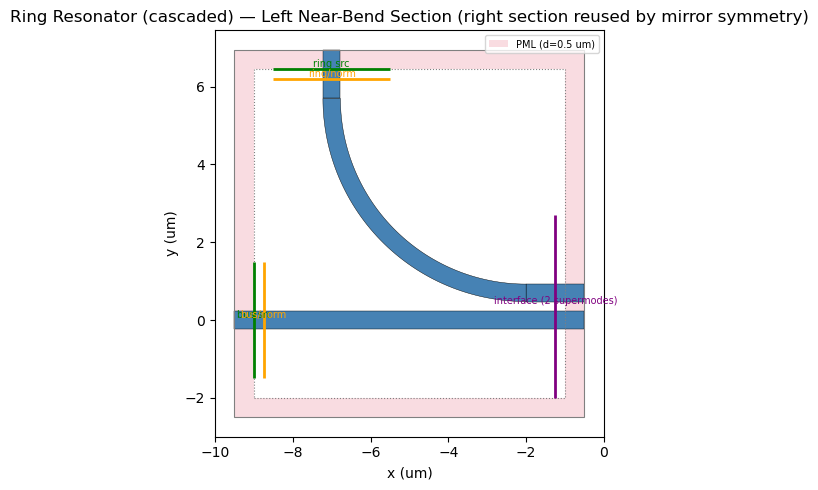

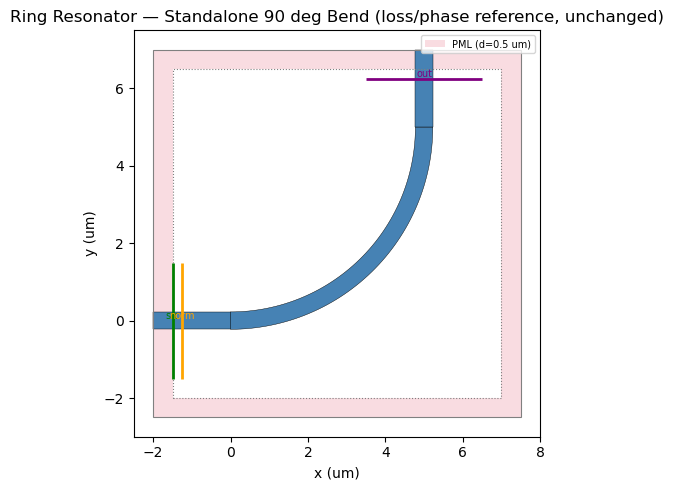

In [13]:
# 10. Geometry preview plots
def plot_cell(polys, cell_size, geometry_center, monitors, title):
    fig, ax = plt.subplots(figsize=(7, 5))
    cx, cy = geometry_center
    sx, sy = cell_size

    outer = mpatches.Rectangle((cx - sx / 2, cy - sy / 2), sx, sy)
    inner = mpatches.Rectangle((cx - sx / 2 + DPML, cy - sy / 2 + DPML), sx - 2 * DPML, sy - 2 * DPML)
    pml_path = mpath.Path.make_compound_path(
        mpath.Path(outer.get_verts()[::-1]), mpath.Path(inner.get_verts())
    )
    ax.add_patch(mpatches.PathPatch(pml_path, facecolor="crimson", alpha=0.15, edgecolor="none",
                                     zorder=0, label="PML"))

    for poly in polys:
        ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor="steelblue", edgecolor="k", lw=0.3))
    ax.add_patch(mpatches.Rectangle((cx - sx / 2, cy - sy / 2), sx, sy, fill=False, edgecolor="gray", lw=0.8))
    ax.add_patch(mpatches.Rectangle((cx - sx / 2 + DPML, cy - sy / 2 + DPML), sx - 2 * DPML, sy - 2 * DPML,
                                     fill=False, edgecolor="gray", linestyle=":", lw=0.8))
    for (kind, x0, y0, x1, y1, label, color) in monitors:
        ax.plot([x0, x1], [y0, y1], color=color, lw=2.0, solid_capstyle="butt")
        ax.annotate(label, (0.5 * (x0 + x1), 0.5 * (y0 + y1)), fontsize=7, color=color,
                    ha="center", va="bottom")
    ax.set_xlim(cx - sx / 2 - 0.5, cx + sx / 2 + 0.5)
    ax.set_ylim(cy - sy / 2 - 0.5, cy + sy / 2 + 0.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x (um)")
    ax.set_ylabel("y (um)")
    ax.set_title(title)
    ax.legend(handles=[mpatches.Patch(facecolor="crimson", alpha=0.15, label=f"PML (d={DPML} um)")],
              loc="upper right", fontsize=7)
    plt.tight_layout()
    plt.show()


def _mon_seg(width, x=None, y=None, xc=None, yc=None):
    if x is not None:
        return (x, yc - width / 2, x, yc + width / 2)
    return (xc - width / 2, y, xc + width / 2, y)


plot_cell(
    build_left_polys(), (LEFT_SX, LEFT_SY), (LEFT_X_CENTER, LEFT_Y_CENTER),
    [
        ("src", *_mon_seg(PORT_APERTURE, x=-INNER_X_HALF, yc=0.0), "bus src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, x=-INNER_X_HALF + MONITOR_MARGIN, yc=0.0), "bus/norm", "orange"),
        ("src", *_mon_seg(PORT_APERTURE, xc=-STUB_X, y=LEFT_STUB_TOP), "ring src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, xc=-STUB_X, y=LEFT_RING_Y), "ring/norm", "orange"),
        ("mon", *_mon_seg(IFACE_WIDTH, x=IFACE_X - MONITOR_MARGIN, yc=IFACE_Y_CENTER), "interface (2 supermodes)", "purple"),
    ],
    "Ring Resonator (cascaded) — Left Near-Bend Section (right section reused by mirror symmetry)",
)
plot_cell(
    build_bend_polys(), (BEND_SX, BEND_SY), (BEND_X_CENTER, BEND_Y_CENTER),
    [
        ("src", *_mon_seg(PORT_APERTURE, x=-STUB_LEN + SOURCE_MARGIN, yc=0.0), "src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, x=-STUB_LEN + MONITOR_MARGIN, yc=0.0), "norm", "orange"),
        ("mon", *_mon_seg(PORT_APERTURE, xc=R, y=R + STUB_LEN - MONITOR_MARGIN), "out", "purple"),
    ],
    "Ring Resonator — Standalone 90 deg Bend (loss/phase reference, unchanged)",
)

In [14]:
# 11. Run the cascade: 2 left-section FDTD excitations + standalone bend
#     FDTD + coupled-pair supermode solve, combined into t/k1/k2/t_ring.
wl_fdtd = np.linspace(WL_MIN, WL_MAX, N_WL_FDTD)
wl_solve = np.linspace(WL_MIN, WL_MAX, N_WL_SOLVE)

print("[1/4] Left-section FDTD, bus-excited...")
M_left_bus = run_left_fdtd("bus", wl_fdtd, save_dir=save_dir, cache_only=CACHE_ONLY)      # [n_wl, N_MODES]

print("[2/4] Left-section FDTD, ring-excited...")
M_left_ring = run_left_fdtd("ring", wl_fdtd, save_dir=save_dir, cache_only=CACHE_ONLY)    # [n_wl, N_MODES]

M_left = np.stack([M_left_bus, M_left_ring], axis=-1)              # [n_wl, N_MODES, 2] cols=[bus_in, ring_in]
M_right = M_left.transpose(0, 2, 1)                                # [n_wl, 2, N_MODES] — reciprocity reuse, NOT resimulated

print("[3/4] Standalone bend FDTD...")
b_raw = run_bend_fdtd(wl_fdtd, save_dir=save_dir, cache_only=CACHE_ONLY)

print(f"[4/4] Coupled-pair (body) supermode solve at {N_WL_SOLVE} wavelengths...")
body_modes = [solve_body_supermodes(wl, save_dir=save_dir, cache_only=CACHE_ONLY) for wl in wl_solve]
neff_even_solve = np.array([m[0] for m in body_modes])
neff_odd_solve = np.array([m[1] for m in body_modes])
neff_even_fit = np.polyfit(wl_solve, neff_even_solve, deg=2)
neff_odd_fit = np.polyfit(wl_solve, neff_odd_solve, deg=2)
neff_even_resid = neff_even_solve - np.polyval(neff_even_fit, wl_solve)
neff_odd_resid = neff_odd_solve - np.polyval(neff_odd_fit, wl_solve)
print(f"  supermode neff fit residual (max abs): even={np.max(np.abs(neff_even_resid)):.2e}, "
      f"odd={np.max(np.abs(neff_odd_resid)):.2e}")

phi_even = 2 * np.pi * np.polyval(neff_even_fit, wl_fdtd) / wl_fdtd * BODY_LENGTH
phi_odd = 2 * np.pi * np.polyval(neff_odd_fit, wl_fdtd) / wl_fdtd * BODY_LENGTH

P_body = np.zeros((N_WL_FDTD, N_MODES, N_MODES), dtype=complex)
P_body[:, 0, 0] = np.exp(1j * phi_even)
P_body[:, 1, 1] = np.exp(1j * phi_odd)

# [bus_out,ring_out] <- 2 supermodes <- [bus_in,ring_in], per wavelength:
_tmp = np.einsum("wij,wjk->wik", P_body, M_left)         # [n_wl, N_MODES, 2]
S_coupler = np.einsum("wij,wjk->wik", M_right, _tmp)     # [n_wl, 2, 2] == M_left.T @ P_body @ M_left, per wl

t = S_coupler[:, 0, 0]        # bus_out  <- bus_in
k1 = S_coupler[:, 1, 0]       # ring_out <- bus_in
k2 = S_coupler[:, 0, 1]       # bus_out  <- ring_in
t_ring = S_coupler[:, 1, 1]   # ring_out <- ring_in

mid = N_WL_FDTD // 2
conserve_a = np.abs(t[mid]) ** 2 + np.abs(k1[mid]) ** 2
conserve_b = np.abs(t_ring[mid]) ** 2 + np.abs(k2[mid]) ** 2
k_mismatch = np.max(np.abs(k1 - k2))
print(f"\nPower-conservation check @ mid-lambda (should be <~1, lossy/leaky by design — "
      f"only 2 of several outgoing ports captured here, same as the monolithic version):")
print(f"  bus-excited path : |t|^2+|k1|^2 = {conserve_a:.4f}")
print(f"  ring-excited path: |t_ring|^2+|k2|^2 = {conserve_b:.4f}")
print(f"  reciprocity check: max|k1-k2| = {k_mismatch:.2e} (should be at/near machine precision — "
      f"S_coupler=M_left.T@P_body@M_left is symmetric BY CONSTRUCTION here, a stronger guarantee "
      f"than the monolithic version's independently-normalized |k1|~=|k2|)")

[1/4] Left-section FDTD, bus-excited...
  [cache] run_left_fdtd('bus') hit -> /Users/jhiesener/Documents/shit/BEEF/examples/example_sim_cache/f90d6cc8c4f64816
[2/4] Left-section FDTD, ring-excited...
  [cache] run_left_fdtd('ring') hit -> /Users/jhiesener/Documents/shit/BEEF/examples/example_sim_cache/c5566a9725a64929
[3/4] Standalone bend FDTD...
  [cache] run_bend_fdtd hit -> /Users/jhiesener/Documents/shit/BEEF/examples/example_sim_cache/6c2f7d6c5669e69c
[4/4] Coupled-pair (body) supermode solve at 13 wavelengths...
  supermode neff fit residual (max abs): even=3.67e-03, odd=3.90e-03

Power-conservation check @ mid-lambda (should be <~1, lossy/leaky by design — only 2 of several outgoing ports captured here, same as the monolithic version):
  bus-excited path : |t|^2+|k1|^2 = 0.9998
  ring-excited path: |t_ring|^2+|k2|^2 = 0.9928
  reciprocity check: max|k1-k2| = 1.76e-16 (should be at/near machine precision — S_coupler=M_left.T@P_body@M_left is symmetric BY CONSTRUCTION here, a str

Bare-strip mode solve at 13 wavelengths...
  neff fit residual (max abs): 3.80e-03


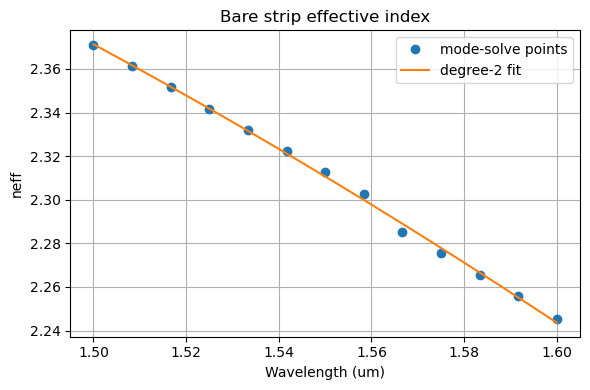

In [15]:
# 12. Mode solve — bare-strip neff(lambda) for the side/far straights and
#     bend reference-plane correction (unchanged from ring_resonator_hybrid.ipynb).
print(f"Bare-strip mode solve at {N_WL_SOLVE} wavelengths...")
neff_solve = np.array([solve_neff(wl, save_dir=save_dir, cache_only=CACHE_ONLY) for wl in wl_solve])
neff_fit = np.polyfit(wl_solve, neff_solve, deg=2)
neff_resid = neff_solve - np.polyval(neff_fit, wl_solve)
print(f"  neff fit residual (max abs): {np.max(np.abs(neff_resid)):.2e}")

fig, ax = plt.subplots(figsize=(6, 4))
wl_fine = np.linspace(WL_MIN, WL_MAX, 200)
ax.plot(wl_solve, neff_solve, "o", label="mode-solve points")
ax.plot(wl_fine, np.polyval(neff_fit, wl_fine), "-", label="degree-2 fit")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("neff")
ax.set_title("Bare strip effective index")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# 13. Dense-grid assembly (unchanged from ring_resonator_hybrid.ipynb — consumes
#     t/k1/k2/t_ring/b_raw/neff_solve exactly the same way regardless of how
#     they were produced).
wl_dense = np.linspace(WL_MIN, WL_MAX, N_WL_DENSE)
neff_dense = np.polyval(neff_fit, wl_dense)

t_d = interp_complex(wl_fdtd, t, wl_dense)
k1_d = interp_complex(wl_fdtd, k1, wl_dense)
k2_d = interp_complex(wl_fdtd, k2, wl_dense)
t_ring_d = interp_complex(wl_fdtd, t_ring, wl_dense)
b_d = interp_complex(wl_fdtd, b_raw, wl_dense)

phi_bend_correction = 2 * np.pi * neff_dense * (BEND_D_IN + BEND_D_OUT) / wl_dense
b_corrected = b_d * np.exp(-1j * phi_bend_correction)

L_outer = 2 * (L_SIDE - S_MON) + L_FAR
phi = 2 * np.pi * neff_dense * L_outer / wl_dense
P = (b_corrected ** 2) * np.exp(1j * phi)

E_thru = t_d + k1_d * k2_d * P / (1.0 - t_ring_d * P)
T = np.abs(E_thru) ** 2

dips = find_dips(wl_dense, T)
if len(dips) >= 2:
    fsr_meas = np.mean(np.diff([d[0] for d in dips]))
else:
    fsr_meas = np.nan
print(f"Dense-grid assembly ({N_WL_DENSE} points): {len(dips)} resonance dip(s) found.")
print(f"  Measured mean FSR: {fsr_meas*1000:.3f} nm (predicted: {FSR_GUESS*1000:.2f} nm)")
if dips:
    print(f"  {'lambda (um)':>12}  {'T_min':>8}  {'FWHM (nm)':>10}  {'Q':>10}")
    for wl0, Tmin, fwhm, q in dips[:10]:
        print(f"  {wl0:12.4f}  {Tmin:8.4f}  {fwhm*1000:10.4f}  {q:10.1f}")

wl_c = wl_dense[len(wl_dense) // 2]
idx = np.argmin(np.abs(wl_dense - wl_c))
print(f"\nResults at lambda = {wl_c:.4f} um:")
print(f"  |t|={np.abs(t_d[idx]):.4f}  |k1|={np.abs(k1_d[idx]):.4f}  |k2|={np.abs(k2_d[idx]):.4f}  "
      f"|t_ring|={np.abs(t_ring_d[idx]):.4f}  |b|={np.abs(b_corrected[idx]):.4f}")
print(f"  T_through = {T[idx]:.4f}  IL = {10*np.log10(max(T[idx],1e-20)):.2f} dB")

smat = SMatrix(wavelengths=wl_dense)
smat.set(E_thru, port="through")
smat.check_passive()  # sanity: total output power must not exceed 1 at any wavelength

Dense-grid assembly (2001 points): 2 resonance dip(s) found.
  Measured mean FSR: 37.400 nm (predicted: 12.87 nm)
   lambda (um)     T_min   FWHM (nm)           Q
        1.5367    0.4486      0.4500      3414.9
        1.5741    0.4726      0.5500      2862.0

Results at lambda = 1.5500 um:
  |t|=0.9698  |k1|=0.2435  |k2|=0.2435  |t_ring|=0.9662  |b|=0.9988
  T_through = 0.9998  IL = -0.00 dB


True

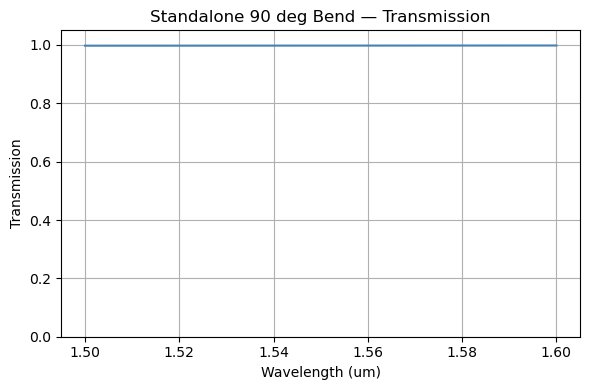

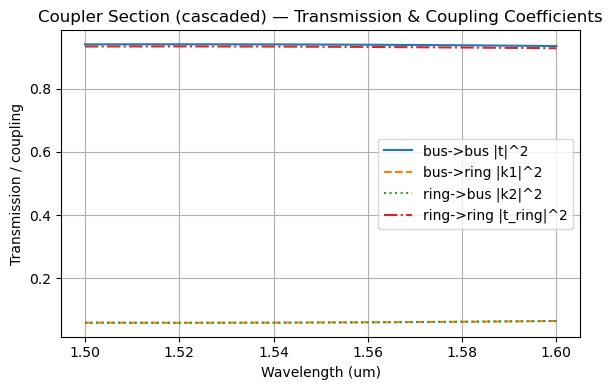

In [17]:
# 14. Independent bend / coupler-region transmission plots (unchanged from
#     ring_resonator_hybrid.ipynb).
T_bend = np.abs(b_d) ** 2

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wl_dense, T_bend, color="steelblue")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("Standalone 90 deg Bend — Transmission")
ax.grid(True)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wl_dense, np.abs(t_d) ** 2, label="bus->bus |t|^2")
ax.plot(wl_dense, np.abs(k1_d) ** 2, linestyle="--", label="bus->ring |k1|^2")
ax.plot(wl_dense, np.abs(k2_d) ** 2, linestyle=":", label="ring->bus |k2|^2")
ax.plot(wl_dense, np.abs(t_ring_d) ** 2, linestyle="-.", label="ring->ring |t_ring|^2")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission / coupling")
ax.set_title("Coupler Section (cascaded) — Transmission & Coupling Coefficients")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

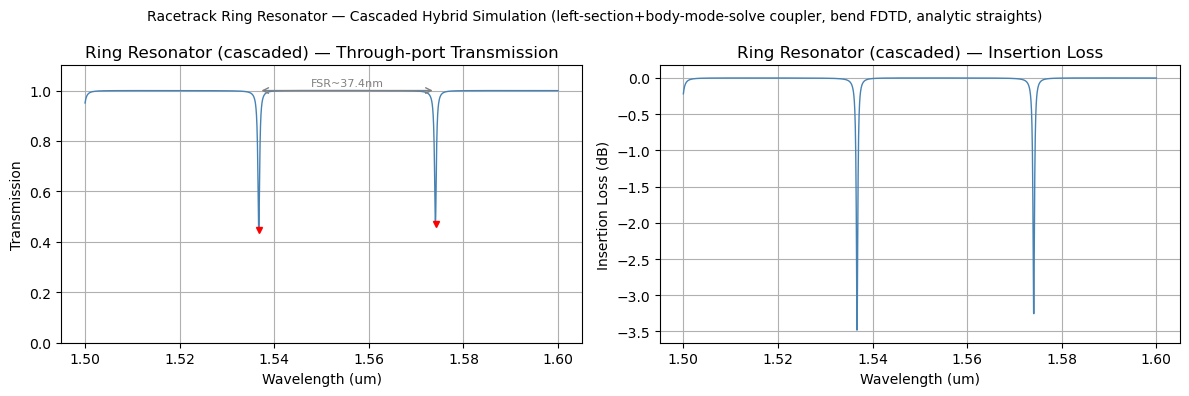

In [18]:
# 15. Results plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(wl_dense, T, color="steelblue", lw=1.0)
for wl0, Tmin, fwhm, q in dips:
    ax.plot(wl0, Tmin, "rv", ms=4)
if len(dips) >= 2:
    ax.annotate("", xy=(dips[1][0], 1.0), xytext=(dips[0][0], 1.0),
                arrowprops=dict(arrowstyle="<->", color="gray"))
    ax.text(0.5 * (dips[0][0] + dips[1][0]), 1.02, f"FSR~{fsr_meas*1000:.1f}nm",
            ha="center", fontsize=8, color="gray")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("Ring Resonator (cascaded) — Through-port Transmission")
ax.grid(True)
ax.set_ylim(0, 1.1)

ax = axes[1]
IL = 10 * np.log10(np.clip(T, 1e-20, None))
ax.plot(wl_dense, IL, color="steelblue", lw=1.0)
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Insertion Loss (dB)")
ax.set_title("Ring Resonator (cascaded) — Insertion Loss")
ax.grid(True)

plt.suptitle("Racetrack Ring Resonator — Cascaded Hybrid Simulation (left-section+body-mode-solve coupler, bend FDTD, analytic straights)",
             fontsize=10)
plt.tight_layout()
plt.show()